In [1]:
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical

np.random.seed(42); tf.random.set_seed(42)
FIG = Path('../report/figures'); FIG.mkdir(parents=True, exist_ok=True)

In [2]:
(X_all, y_all), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

def prep(X): return (X.astype('float32') / 255.0)[..., None]

X_train, X_val = prep(X_all[:55000]), prep(X_all[55000:])
X_test = prep(X_test)
y_train = to_categorical(y_all[:55000], 10)
y_val   = to_categorical(y_all[55000:], 10)
y_test  = to_categorical(y_test, 10)
print(X_train.shape, X_val.shape, X_test.shape)

(55000, 28, 28, 1) (5000, 28, 28, 1) (10000, 28, 28, 1)


In [3]:
model = Sequential([
    Conv2D(16, (3,3), activation='relu', input_shape=(28,28,1), padding='same'),
    MaxPooling2D(2,2),
    Conv2D(32, (3,3), activation='relu', padding='same'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax'),
])
model.summary()

d:\MatKul\Semester 7\Desain SOC\CNN_Robustness_MNIST\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,866 (413.54 KB)

 Trainable params: 105,866 (413.54 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['acc'])
history = model.fit(X_train, y_train, epochs=10, batch_size=100,
                    validation_data=(X_val, y_val))

Epoch 1/10
550/550 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - acc: 0.9261 - loss: 0.2545 - val_acc: 0.9800 - val_loss: 0.0771
Epoch 2/10
550/550 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - acc: 0.9784 - loss: 0.0708 - val_acc: 0.9850 - val_loss: 0.0595
Epoch 3/10
550/550 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - acc: 0.9850 - loss: 0.0492 - val_acc: 0.9876 - val_loss: 0.0477
Epoch 4/10
550/550 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - acc: 0.9884 - loss: 0.0377 - val_acc: 0.9886 - val_loss: 0.0441
Epoch 5/10
550/550 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - acc: 0.9912 - loss: 0.0294 - val_acc: 0.9892 - val_loss: 0.0435
Epoch 6/10
550/550 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - acc: 0.9932 - loss: 0.0235 - val_acc: 0.9890 - val_loss: 0.0466
Epoch 7/10
550/550 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - acc: 0.9943 - loss: 0.0191 - val_acc: 0.9888 - val_loss: 0.0493
Epoch 8/10
550/550 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - acc: 0.9954 - loss: 0.0157 - val_acc: 0.9872 - val_loss: 0.0510
Epoch 9/10
550/550 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - a

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9874 - loss: 0.0431
Test loss: 0.0431 | Test acc: 0.9874


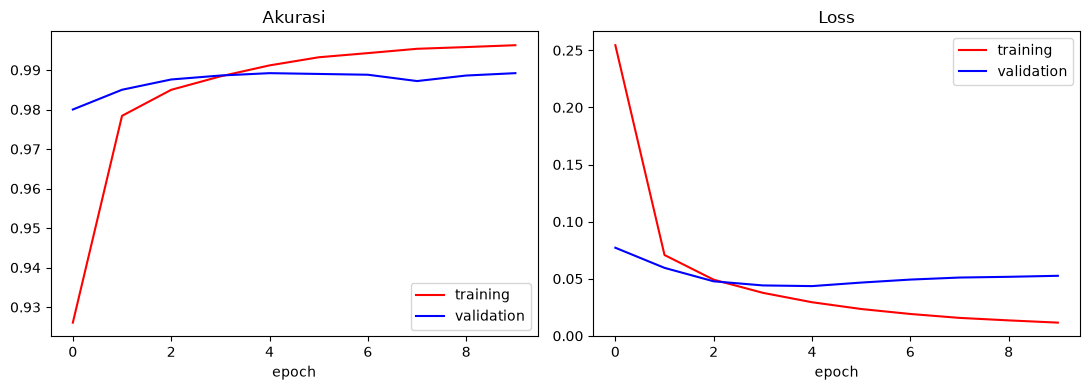

In [5]:
loss, acc = model.evaluate(X_test, y_test)
print(f'Test loss: {loss:.4f} | Test acc: {acc:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history['acc'], 'r', label='training')
ax[0].plot(history.history['val_acc'], 'b', label='validation')
ax[0].set_title('Akurasi'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(history.history['loss'], 'r', label='training')
ax[1].plot(history.history['val_loss'], 'b', label='validation')
ax[1].set_title('Loss'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG/'training_curve.png', dpi=150); plt.show()

In [6]:
pred = model.predict(X_test[:1])
print('label actual:', np.argmax(y_test[0]), '| label prediction:', np.argmax(pred[0]))

model.save('model_cnn_mnist.keras')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step
label actual: 7 | label prediction: 7


In [7]:
import sys; sys.path.append('.')
from perturbations import add_gaussian_noise, add_blur, add_rotation

rng = np.random.default_rng(0)
idx = lambda: rng.choice(len(X_train), 6000, replace=False)

parts, labels = [X_train], [y_train]
for s in (0.1, 0.3, 0.5):                       # noise
    i = idx(); parts.append(add_gaussian_noise(X_train[i], s, seed=int(s*100))); labels.append(y_train[i])
for s in (0.5, 1.0, 1.5):                       # blur
    i = idx(); parts.append(add_blur(X_train[i], s)); labels.append(y_train[i])
for a in (-30, -15, 15, 30):                    # rotasi
    i = idx(); parts.append(add_rotation(X_train[i], a)); labels.append(y_train[i])

X_aug = np.concatenate(parts); y_aug = np.concatenate(labels)
p = rng.permutation(len(X_aug)); X_aug, y_aug = X_aug[p], y_aug[p]
print(X_aug.shape)

(115000, 28, 28, 1)


In [ ]:
done